# Dipole Fit

# Batch Wise Run
Run the code for all subjects of a given dataset.

## 📦 Imports

## 🧠 Data

## ♾️ Loop

# Step Wise Run

Run the code step by step for a single subject.

## 📦 Imports

In [8]:
import mindmap as mm
import mne

## 🧠 Data

In [21]:
# configuration
config = mm.io.read_config("../configurations/simf.yml")
sub    = config["SUBS"][0]
samp   = config["SAMP"][0]

# data
data      = mm.io.read_dataset(sub, "eeg_inv", "bem", sample=samp)
noise_cov = mne.make_ad_hoc_cov(data["eeg_inv"].info, std={"eeg":1})
sfreq     = data["eeg_inv"].info["sfreq"]

# 50% rising phase and peak phase
_, ht = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=0.5)
_, pt = mm.utils.eeg_rising_phase(data["eeg_inv"], ratio=1)

thalf = ht/sfreq 
tpeak = pt/sfreq

DATA SUMMARY
Dataset: simf
Subject: vepcon_sub-10
Retrieved objects:
- eeg_inv
- bem
Missing objects:


## EEG
🛠️ **<font color=violet>Select a time window</font>**:
- `center`: Center of the time window (`tpeak` or `thalf`)
- `win_size`: Window size in [s]

Number of samples: 26


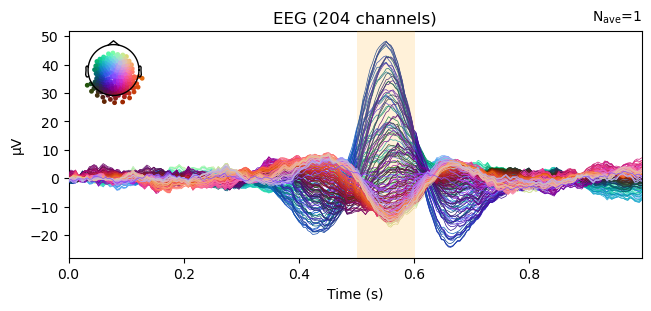

In [48]:
########################### Parameters ###############################
center   = tpeak
win_size = 0.1      # in [s]
######################################################################

eeg = data["eeg_inv"].copy()

# apply average reference
eeg, _ = mne.set_eeg_reference(eeg, ref_channels="average", verbose="warning")

# crop region of interest
dt   = int(win_size * sfreq /2)
tmin = center - (win_size/2)
tmax = center + (win_size/2)
eeg  = eeg.crop(tmin, tmax, include_tmax=True, verbose="warning")

# plot
print(f"Number of samples: {eeg.data.shape[1]}")
_ = data["eeg_inv"].plot(highlight=[tmin,tmax])

## Dipole Fitting

In [49]:
stc = mne.fit_dipole(eeg, noise_cov, data["bem"])

BEM               : [{'id': 4, 'sigma': 0.33000001311302185, 'np': 2562, 'ntri': 5120, 'coord_frame': 5, 'rr': array([[-0.00014885, -0.00699921,  0.10359908],
       [ 0.06619449, -0.00697118,  0.06249403],
       [ 0.02418485,  0.06624299,  0.0686115 ],
       ...,
       [ 0.01389897,  0.01557   , -0.11206023],
       [ 0.00263624,  0.01906882, -0.11207863],
       [ 0.00531365,  0.00830772, -0.11104871]]), 'nn': array([[ 0.02177731,  0.01682122,  0.99962133],
       [ 0.89033902,  0.06302396,  0.45091507],
       [ 0.41144249,  0.71458685,  0.5657568 ],
       ...,
       [ 0.09535929,  0.12933549, -0.98700505],
       [ 0.00524773,  0.20190756, -0.9793905 ],
       [-0.01675995, -0.08069853, -0.99659765]]), 'tris': array([[   0,  644,  642],
       [ 642,  643,  162],
       [ 644,  643,  642],
       ...,
       [2561, 2201,  557],
       [2477, 2201, 2561],
       [2477,   11, 2201]], dtype=int32)}, {'id': 3, 'sigma': 0.006000000052154064, 'np': 2562, 'ntri': 5120, 'coord_frame':

TypeError: [{'id': 4, 'sigma': 0.33000001311302185, 'np': 2562, 'ntri': 5120, 'coord_frame': 5, 'rr': array([[-0.00014885, -0.00699921,  0.10359908],
       [ 0.06619449, -0.00697118,  0.06249403],
       [ 0.02418485,  0.06624299,  0.0686115 ],
       ...,
       [ 0.01389897,  0.01557   , -0.11206023],
       [ 0.00263624,  0.01906882, -0.11207863],
       [ 0.00531365,  0.00830772, -0.11104871]]), 'nn': array([[ 0.02177731,  0.01682122,  0.99962133],
       [ 0.89033902,  0.06302396,  0.45091507],
       [ 0.41144249,  0.71458685,  0.5657568 ],
       ...,
       [ 0.09535929,  0.12933549, -0.98700505],
       [ 0.00524773,  0.20190756, -0.9793905 ],
       [-0.01675995, -0.08069853, -0.99659765]]), 'tris': array([[   0,  644,  642],
       [ 642,  643,  162],
       [ 644,  643,  642],
       ...,
       [2561, 2201,  557],
       [2477, 2201, 2561],
       [2477,   11, 2201]], dtype=int32)}, {'id': 3, 'sigma': 0.006000000052154064, 'np': 2562, 'ntri': 5120, 'coord_frame': 5, 'rr':

## Apply Dipole Fitting

## Ground Truth

#### 💾 **Save result**